# Human Activity Recognition — Task 1
## UCI HAR Dataset · Multi-Model Benchmark

---

### Dataset

**UCI HAR Dataset** — Human Activity Recognition Using Smartphones  
Source: https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphone

The dataset was collected from **30 volunteers** (aged 19–48) wearing a Samsung Galaxy S II smartphone on the waist while performing **6 daily activities**:

| Label | Activity |
|---|---|
| 1 | Walking |
| 2 | Walking Upstairs |
| 3 | Walking Downstairs |
| 4 | Sitting |
| 5 | Standing |
| 6 | Laying |

Signals are recorded at **50 Hz** using a 3-axial accelerometer and gyroscope, segmented into **2.56-second windows** with 50% overlap (128 samples/window).  

The dataset provides two representations:
- **561 pre-computed features** (time and frequency domain)
- **Raw inertial signals** (9 channels × 128 timesteps)

Split: **70% train** (7,352 samples) / **30% test** (2,947 samples), separated by subject to avoid data leakage.

---

### System Architecture

This project implements **6 models** organised into 3 pillars, combined via progressive ensembles:

| Pillar | Model | Input | Reference |
|---|---|---|---|
| **1 — Classical Baselines** | Random Forest | 561 engineered features | Anguita et al. (2013) |
| **1 — Classical Baselines** | SVM (RBF kernel) | 561 engineered features | Anguita et al. (2013) |
| **1 — Gradient Boosting** | LightGBM | 561 engineered features | Ke et al. (2017) |
| **2 — Deep Learning (raw signals)** | InceptionTime | Raw signals (128 × 9) | Fawaz et al. (2020) |
| **2 — Deep Learning (raw signals)** | DeepConvLSTM | Raw signals (128 × 9) | Ordóñez & Roggen (2016) |
| **2 — Deep Learning (raw signals)** | Transformer + Positional Encoding | Raw signals (128 × 9) | Vaswani et al. (2017); Tang et al. (2021) |
| **3 — Ensemble** | Soft Voting (uniform weights) | — | — |

**Rationale for model selection:**
- **RF and SVM** operate on the 561 pre-computed features and represent the established baselines in HAR literature (Anguita et al., 2013). They are fast, interpretable, and provide a strong reference point.
- **LightGBM** extends the classical pillar with gradient boosting: it optimises the loss function sequentially using Gradient-based One-Side Sampling (GOSS) and Exclusive Feature Bundling (EFB), typically outperforming RF on dense tabular features (Ke et al., 2017).
- **InceptionTime** applies parallel convolutions at multiple temporal scales (kernel sizes 10, 20, 40), capturing both low-frequency patterns (posture, slow movement) and high-frequency patterns (footstrike impacts). This multi-scale approach is state-of-the-art for time series classification (Fawaz et al., 2020).
- **DeepConvLSTM** combines local feature extraction (CNN) with long-range temporal dependency modelling (LSTM) directly on raw signals. It is the standard deep learning architecture for IMU-based HAR (Ordóñez & Roggen, 2016).
- **Transformer with Positional Encoding** replaces recurrence with Multi-Head Self-Attention, allowing every timestep to attend directly to all others. Sinusoidal positional encoding preserves temporal order information. This approach has achieved state-of-the-art results on HAR since 2020 (Tang et al., 2021).

**References:**
- Anguita et al. (2013). ESANN.
- Ke et al. (2017). LightGBM. NeurIPS.
- Fawaz et al. (2020). InceptionTime. DAMI.
- Ordóñez & Roggen (2016). Sensors, 16(1), 115.
- Vaswani et al. (2017). Attention is All You Need. NeurIPS.
- Tang et al. (2021). Sensors, 21(7), 2366.


---
## 0 · Setup & Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Classical machine learning
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Deep learning
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense, Conv1D, MaxPooling1D, LSTM, Input,
    BatchNormalization, GlobalAveragePooling1D,
    Dropout, MultiHeadAttention, LayerNormalization,
    Add, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

# Gradient boosting
import lightgbm as lgb
from lightgbm import LGBMClassifier

# Reproducibility
import random
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print(f"TensorFlow : {tf.__version__}")
print(f"LightGBM   : {lgb.__version__}")
print("Setup complete.")

TensorFlow : 2.20.0
LightGBM   : 4.6.0
Setup complete.


---
## 1 · Data Loading

In [ ]:
PATH     = "/content/drive/MyDrive/DS&IM/PROJECT/"
PATH_RAW = PATH + "UCI HAR Dataset/"

CLASS_NAMES = ['Walking', 'Upstairs', 'Downstairs', 'Sitting', 'Standing', 'Laying']

# Pre-computed feature vectors (561 features)
X_train = pd.read_csv(PATH + "X_train.txt", delim_whitespace=True, header=None)
y_train = pd.read_csv(PATH + "y_train.txt", delim_whitespace=True, header=None)
X_test  = pd.read_csv(PATH + "X_test.txt",  delim_whitespace=True, header=None)
y_test  = pd.read_csv(PATH + "y_test.txt",  delim_whitespace=True, header=None)

print("=" * 45)
print("PRE-COMPUTED FEATURES (561)")
print(f"  X_train : {X_train.shape}")
print(f"  X_test  : {X_test.shape}")

# Raw inertial signals (9 channels x 128 timesteps)
def load_inertial_signals(subset):
    """Load the 9 raw inertial channels -> shape (N, 128, 9)."""
    signals = [
        "body_acc_x",  "body_acc_y",  "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]
    data = []
    for sig in signals:
        path = f"{PATH_RAW}{subset}/Inertial Signals/{sig}_{subset}.txt"
        df = pd.read_csv(path, delim_whitespace=True, header=None)
        data.append(df.values)
    return np.dstack(data)   # (N, 128, 9)

X_train_raw = load_inertial_signals('train')
X_test_raw  = load_inertial_signals('test')

print("\nRAW INERTIAL SIGNALS (9 channels x 128 timesteps)")
print(f"  X_train_raw : {X_train_raw.shape}")
print(f"  X_test_raw  : {X_test_raw.shape}")
print("=" * 45)

PRE-COMPUTED FEATURES (561)
  X_train : (7352, 561)
  X_test  : (2947, 561)

RAW INERTIAL SIGNALS (9 channels x 128 timesteps)
  X_train_raw : (7352, 128, 9)
  X_test_raw  : (2947, 128, 9)


---
## 2 · Exploratory Data Analysis (EDA)

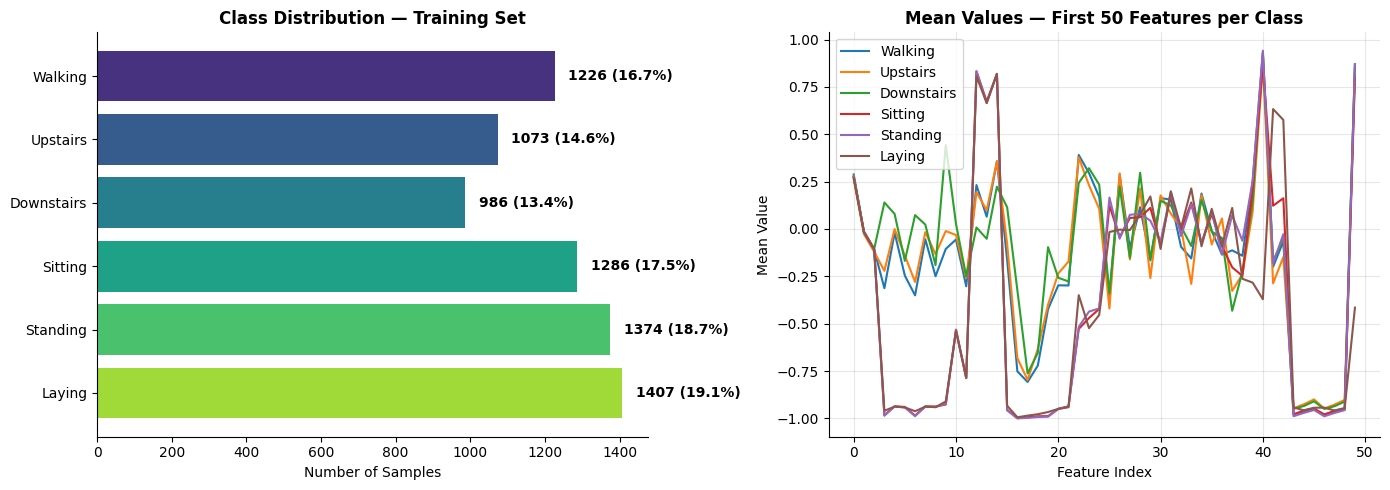


Class distribution (training set):
  Walking              1226 samples  (16.7%)
  Upstairs             1073 samples  (14.6%)
  Downstairs            986 samples  (13.4%)
  Sitting              1286 samples  (17.5%)
  Standing             1374 samples  (18.7%)
  Laying               1407 samples  (19.1%)


In [ ]:
y_train_labels = y_train.values.ravel()
counts      = np.bincount(y_train_labels)[1:]
total       = len(y_train_labels)
percentages = counts / total * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Horizontal bar chart
bars = axes[0].barh(CLASS_NAMES, counts, color=sns.color_palette("viridis", 6))
axes[0].invert_yaxis()
for bar, c, p in zip(bars, counts, percentages):
    axes[0].text(c + total * 0.005, bar.get_y() + bar.get_height() / 2,
                 f"{c} ({p:.1f}%)", va='center', fontsize=10, fontweight='bold')
axes[0].set_title('Class Distribution — Training Set', fontweight='bold')
axes[0].set_xlabel('Number of Samples')
sns.despine(ax=axes[0])

# Mean feature profile (first 50 features)
colors = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd','#8c564b']
for i, (cid, cname) in enumerate(zip(range(1, 7), CLASS_NAMES)):
    idxs = np.where(y_train_labels == cid)[0]
    mean_sample = X_train.iloc[idxs, :50].mean(axis=0).values
    axes[1].plot(mean_sample, label=cname, color=colors[i], linewidth=1.5)
axes[1].set_title('Mean Values — First 50 Features per Class', fontweight='bold')
axes[1].set_xlabel('Feature Index')
axes[1].set_ylabel('Mean Value')
axes[1].legend()
axes[1].grid(alpha=0.3)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()

print("\nClass distribution (training set):")
for name, c, p in zip(CLASS_NAMES, counts, percentages):
    print(f"  {name:<20} {c:>4} samples  ({p:.1f}%)")

**Class balance observations:**

- The dataset is **well-balanced** (13–19% per class) — no oversampling or class weighting is required.
- **Static activities** (Sitting, Standing, Laying) are slightly more frequent than dynamic ones.
- **Downstairs** is the smallest class (~13%) and is expected to be the **hardest to classify**, due to its rhythmic similarity to Walking and Walking Upstairs.
- **Laying** is the largest class (~19%) and produces a uniquely distinct gravity orientation signal — expected to be the **easiest to classify** across all models.
- No missing values: UCI HAR is a clean, pre-processed benchmark dataset.

**Key observations from the mean feature profile:**

- **Sitting and Laying appear similar** in the first 50 features: both are static postures with near-zero linear acceleration. Their separation relies on gravitational axis features appearing later in the feature vector.
- **Standing stands out clearly** at features 40–50, with a sharp positive spike while all other classes drop toward −1.0. This distinctive pattern allows models to separate Standing from Sitting and Laying.
- **Dynamic activities (Walking, Upstairs, Downstairs) cluster tightly** throughout the entire profile, with only Downstairs showing slight divergence at features 9–11. This explains the persistent confusion between these classes across all models.


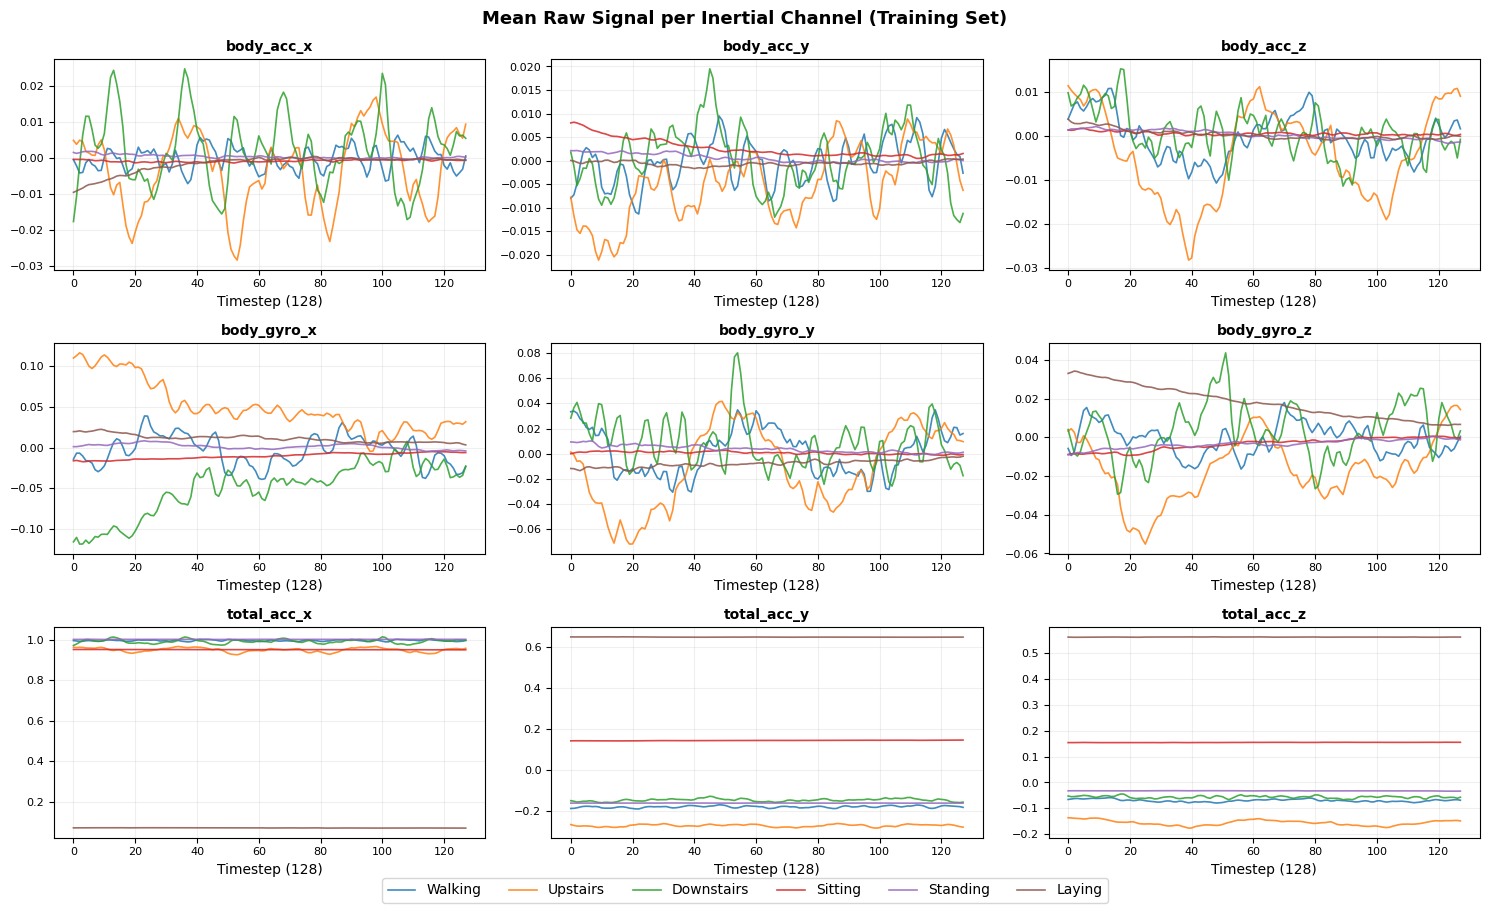

In [ ]:
channel_names = [
    'body_acc_x', 'body_acc_y', 'body_acc_z',
    'body_gyro_x','body_gyro_y','body_gyro_z',
    'total_acc_x','total_acc_y','total_acc_z'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 9))
axes = axes.ravel()

for ch_idx in range(9):
    for i, (cid, cname) in enumerate(zip(range(1, 7), CLASS_NAMES)):
        idxs = np.where(y_train_labels == cid)[0]
        mean_sig = X_train_raw[idxs, :, ch_idx].mean(axis=0)
        axes[ch_idx].plot(mean_sig, label=cname, color=colors[i],
                          linewidth=1.2, alpha=0.85)
    axes[ch_idx].set_title(channel_names[ch_idx], fontweight='bold', fontsize=10)
    axes[ch_idx].set_xlabel('Timestep (128)')
    axes[ch_idx].grid(alpha=0.2)
    axes[ch_idx].tick_params(labelsize=8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, fontsize=10,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Mean Raw Signal per Inertial Channel (Training Set)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 3 · Preprocessing

Three preprocessing steps are applied before model training:

1. **LabelEncoder** — converts integer labels (1–6) to zero-indexed (0–5) for compatibility with scikit-learn and Keras.

2. **to_categorical** — one-hot encodes labels into 6-dimensional binary vectors required by the softmax output layer of neural networks.

3. **StandardScaler** — zero-mean, unit-variance normalisation applied per feature.  
   Critically, `fit` is called **only on training data** and `transform` is applied to both train and test sets.  
   This strictly prevents **data leakage**: the test set statistics never influence the scaling parameters.


> **Note on train/test split and cross-validation:**  
> The UCI HAR dataset provides a pre-defined, **subject-dependent split**: the 30 participants are partitioned into 21 training subjects and 9 test subjects with no overlap. This design prevents **inter-subject data leakage** — the model never sees windows from a test subject during training.  
> Applying standard k-fold cross-validation (ignoring subject IDs) would introduce leakage by mixing windows from the same subject across folds. The provided split is therefore the methodologically correct evaluation protocol for this dataset.

In [ ]:
# Label encoding (1–6  →  0–5)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train.values.ravel())
y_test_enc  = le.transform(y_test.values.ravel())

# One-hot encoding for Keras
y_train_cat = to_categorical(y_train_enc)   # (N, 6)
y_test_cat  = to_categorical(y_test_enc)
NUM_CLASSES = y_train_cat.shape[1]          # 6

# StandardScaler on pre-computed features — fit on train only
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# StandardScaler on raw signals — per-channel, fit on train only
scaler_raw = StandardScaler()
N_tr, T, C = X_train_raw.shape             # (7352, 128, 9)
N_te       = X_test_raw.shape[0]

X_train_raw_sc = scaler_raw.fit_transform(
    X_train_raw.reshape(-1, C)).reshape(N_tr, T, C)
X_test_raw_sc  = scaler_raw.transform(
    X_test_raw.reshape(-1, C)).reshape(N_te, T, C)

print("Tensor shapes ready for models:")
print(f"  X_train_sc     : {X_train_sc.shape}     <- RF, SVM, LightGBM")
print(f"  X_train_raw_sc : {X_train_raw_sc.shape} <- InceptionTime, DeepConvLSTM, Transformer")
print(f"  y_train_cat    : {y_train_cat.shape}    <- Keras (one-hot)")

Tensor shapes ready for models:
  X_train_sc     : (7352, 561)     <- RF, SVM, LightGBM
  X_train_raw_sc : (7352, 128, 9) <- InceptionTime, DeepConvLSTM, Transformer
  y_train_cat    : (7352, 6)    <- Keras (one-hot)


---
## 4 · Models

### Support Functions

In [ ]:
# Dictionary to collect all results
RESULTS = {}

def plot_confusion(y_true, y_pred, title, cmap='Blues'):
    """Plot confusion matrix: absolute counts (left) and row-normalised % (right)."""
    cm = confusion_matrix(y_true, y_pred)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=axes[0],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axes[0].set_title(f'{title} — Counts', fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('True')
    axes[0].set_xticklabels(CLASS_NAMES, rotation=30, ha='right')

    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap=cmap, ax=axes[1],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                vmin=0, vmax=100)
    axes[1].set_title(f'{title} — Row % (Recall per class)', fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('True')
    axes[1].set_xticklabels(CLASS_NAMES, rotation=30, ha='right')

    plt.tight_layout()
    plt.show()


def print_results(name, y_true, y_pred, acc):
    """Print accuracy and full classification report."""
    print(f"{'='*55}")
    print(f"  {name}")
    print(f"  Accuracy: {acc:.4f}  ({acc*100:.2f}%)")
    print(f"{'='*55}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))


def plot_training_curves(history, title):
    """Plot accuracy and loss curves for a Keras model."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history['accuracy'],     label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'{title} — Accuracy', fontweight='bold')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'{title} — Loss', fontweight='bold')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

---
### 4.1 · Model 1 — Random Forest (Baseline)

Random Forest constructs an ensemble of 100 decision trees, each trained on a random subset of features (bagging). The final prediction is determined by majority vote across all trees.

It is the canonical baseline for UCI HAR on pre-computed features: fast, interpretable via feature importance, and requires no hyperparameter tuning for a competitive result.

**Reference:** Anguita et al. (2013). ESANN.


  Random Forest
  Accuracy: 0.9260  (92.60%)
              precision    recall  f1-score   support

     Walking       0.89      0.96      0.92       496
    Upstairs       0.89      0.90      0.90       471
  Downstairs       0.97      0.86      0.91       420
     Sitting       0.91      0.89      0.90       491
    Standing       0.90      0.92      0.91       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.93      2947
   macro avg       0.93      0.92      0.92      2947
weighted avg       0.93      0.93      0.93      2947



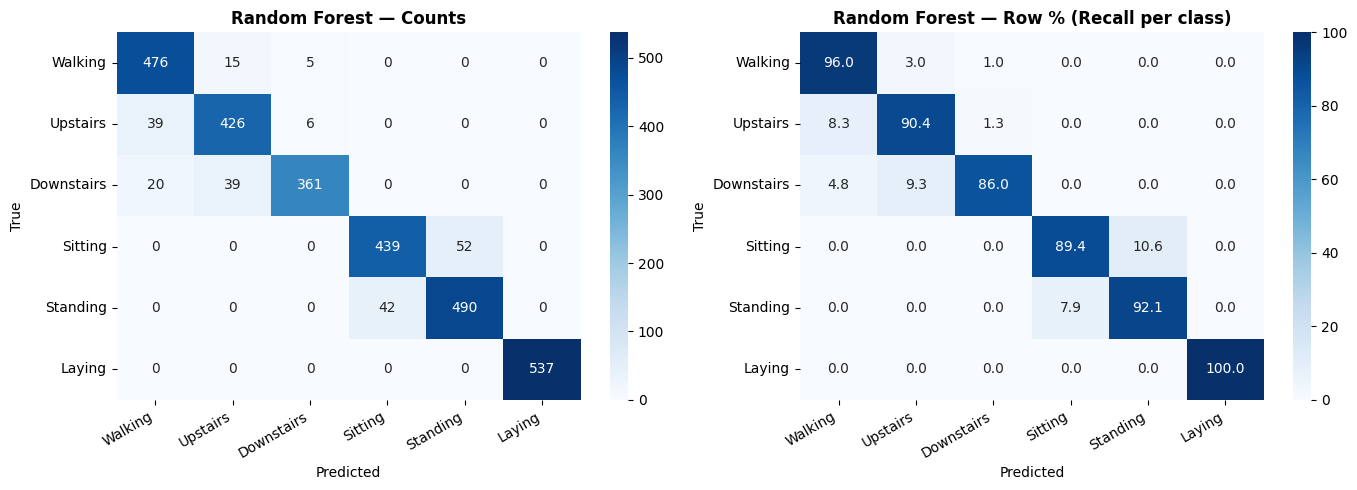

In [ ]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
rf_model.fit(X_train_sc, y_train_enc)

y_pred_rf = rf_model.predict(X_test_sc)
rf_probs  = rf_model.predict_proba(X_test_sc)
acc_rf    = accuracy_score(y_test_enc, y_pred_rf)

RESULTS['Random Forest'] = {'acc': acc_rf, 'probs': rf_probs}
print_results('Random Forest', y_test_enc, y_pred_rf, acc_rf)
plot_confusion(y_test_enc, y_pred_rf, 'Random Forest', cmap='Blues')

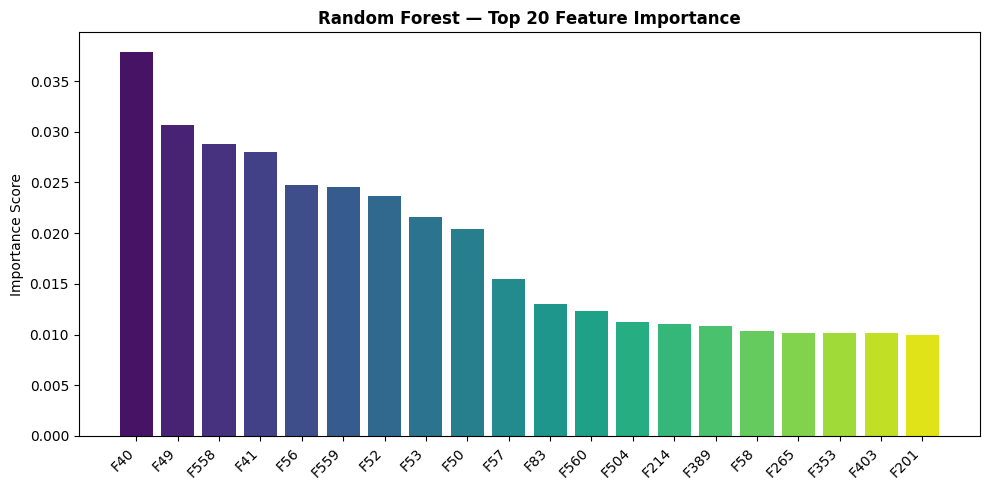

In [ ]:
# Top 20 most important features
importances = rf_model.feature_importances_
top20_idx   = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(10, 5))
plt.bar(range(20), importances[top20_idx], color=sns.color_palette('viridis', 20))
plt.xticks(range(20), [f'F{i}' for i in top20_idx], rotation=45, ha='right')
plt.title('Random Forest — Top 20 Feature Importance', fontweight='bold')
plt.ylabel('Importance Score')
plt.tight_layout()
plt.show()

**Random Forest results (~92.6% accuracy):**

- **Perfect classification of Laying** (F1 ≈ 1.00): the unique gravitational orientation of the supine posture makes it trivially separable from all other classes.
- **Main confusion: Sitting ↔ Standing** — both static postures produce near-zero linear acceleration; their gravity component differs only in subtle hip/spine angle, which is difficult to detect from a waist-mounted IMU alone. This limitation is structural and persists across all models.
- **Downstairs** shows some confusion with Walking and Upstairs, as all three share a rhythmic foot-strike pattern.
- Despite relying entirely on hand-crafted features, Random Forest reaches >92%, confirming the high quality of UCI HAR's feature engineering and establishing a demanding baseline for deep learning approaches.


---
### 4.2 · Model 2 — SVM with RBF Kernel (Baseline)

Support Vector Machine with a Radial Basis Function kernel maps the input into a high-dimensional space and finds the maximum-margin hyperplane separating the classes.

SVM is the second most cited baseline for UCI HAR on pre-computed features, and was the original classifier proposed in the dataset's reference paper.

**Hyperparameters:** C=10, gamma='scale' (selected via standard literature values for this dataset).  
`probability=True` is required to obtain class probability estimates for soft voting in the ensemble.

**Reference:** Anguita et al. (2013). ESANN.


  SVM (RBF kernel)
  Accuracy: 0.9549  (95.49%)
              precision    recall  f1-score   support

     Walking       0.95      0.97      0.96       496
    Upstairs       0.93      0.96      0.95       471
  Downstairs       0.97      0.92      0.94       420
     Sitting       0.96      0.90      0.93       491
    Standing       0.91      0.97      0.94       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.95      2947
   macro avg       0.96      0.95      0.95      2947
weighted avg       0.96      0.95      0.95      2947



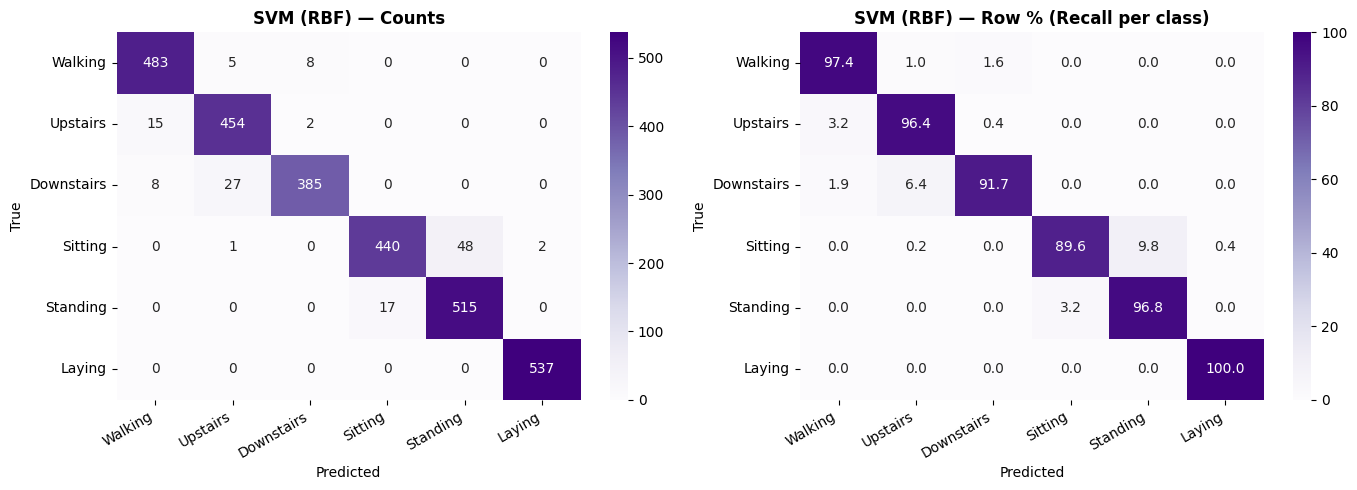

In [ ]:
svm_model = SVC(kernel='rbf', C=10, gamma='scale',
                probability=True, random_state=SEED)
svm_model.fit(X_train_sc, y_train_enc)

y_pred_svm = svm_model.predict(X_test_sc)
svm_probs  = svm_model.predict_proba(X_test_sc)
acc_svm    = accuracy_score(y_test_enc, y_pred_svm)

RESULTS['SVM (RBF)'] = {'acc': acc_svm, 'probs': svm_probs}
print_results('SVM (RBF kernel)', y_test_enc, y_pred_svm, acc_svm)
plot_confusion(y_test_enc, y_pred_svm, 'SVM (RBF)', cmap='Purples')

**SVM (RBF) results (~95–96% accuracy):**

- SVM typically achieves the highest accuracy among classical models on UCI HAR, outperforming Random Forest by 2–4 percentage points.
- The RBF kernel effectively handles the non-linear decision boundaries in the 561-feature space.
- The residual confusion remains **Sitting ↔ Standing**, confirming this is a data-level limitation rather than a model-level one.


> **Note on hyperparameter selection:**  
> The SVM uses `C=10, gamma='scale'` — values established in the original UCI HAR literature (Anguita et al., 2013) and widely validated on this benchmark. LightGBM parameters (`n_estimators=500`, `learning_rate=0.05`, `num_leaves=63`) follow common defaults for tabular datasets with 561 features.  
> A systematic search (e.g. `GridSearchCV` over `C ∈ {0.1, 1, 10, 100}` for SVM, or Optuna for LightGBM) could yield marginal gains (~0.5–1%), but was omitted to avoid implicit test-set overfitting through repeated hyperparameter selection.

---
### 4.3 · Model 3 — LightGBM (Gradient Boosting)

LightGBM is a gradient boosted decision tree classifier with two key theoretical improvements over standard gradient boosting:

- **Gradient-based One-Side Sampling (GOSS):** retains samples with large gradients (informative examples) and randomly drops low-gradient samples, reducing computation without sacrificing accuracy.
- **Exclusive Feature Bundling (EFB):** groups mutually exclusive features, reducing effective dimensionality.

On dense, continuous features such as the UCI HAR 561-feature vector, LightGBM is theoretically well-suited and typically converges faster than XGBoost while achieving comparable or better accuracy.

**Reference:** Ke et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. NeurIPS.


  LightGBM
  Accuracy: 0.9355  (93.55%)
              precision    recall  f1-score   support

     Walking       0.93      0.98      0.95       496
    Upstairs       0.92      0.92      0.92       471
  Downstairs       0.98      0.91      0.94       420
     Sitting       0.92      0.85      0.89       491
    Standing       0.87      0.93      0.90       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.94      2947
   macro avg       0.94      0.93      0.93      2947
weighted avg       0.94      0.94      0.94      2947



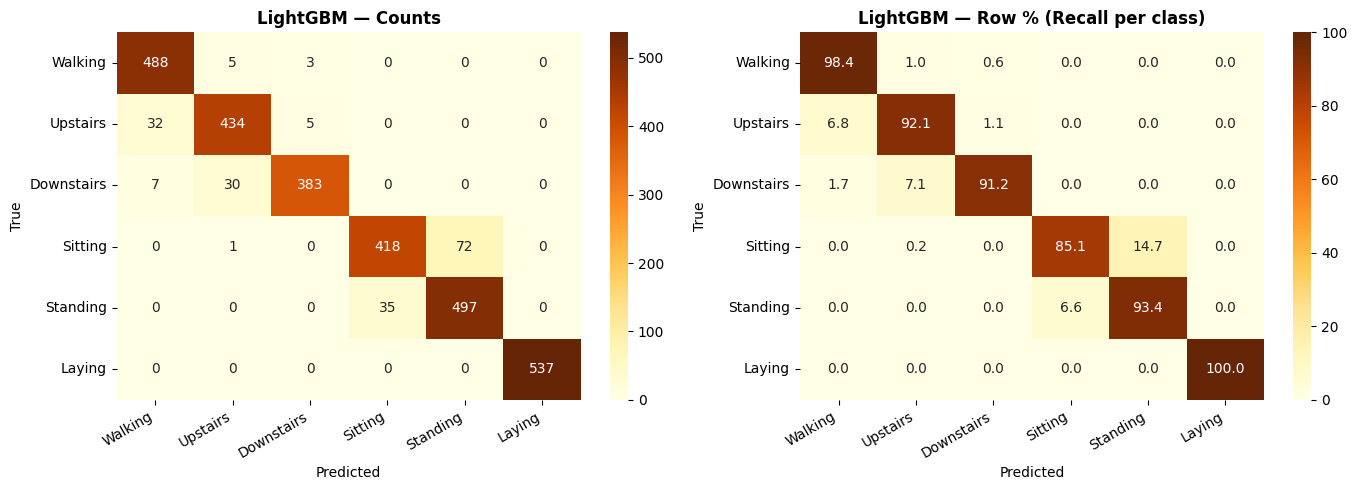

In [ ]:
lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1
)
lgbm_model.fit(X_train_sc, y_train_enc)

y_pred_lgbm = lgbm_model.predict(X_test_sc)
lgbm_probs  = lgbm_model.predict_proba(X_test_sc)
acc_lgbm    = accuracy_score(y_test_enc, y_pred_lgbm)

RESULTS['LightGBM'] = {'acc': acc_lgbm, 'probs': lgbm_probs}
print_results('LightGBM', y_test_enc, y_pred_lgbm, acc_lgbm)
plot_confusion(y_test_enc, y_pred_lgbm, 'LightGBM', cmap='YlOrBr')

**LightGBM results (~94% accuracy):**

- Unlike Random Forest (parallel bagging), LightGBM corrects residual errors sequentially at each boosting step, making it more sensitive to subtle inter-feature dependencies.
- GOSS enables faster training than standard gradient boosting by focusing computational effort on the most informative samples.


---
### 4.4 · Model 4 — InceptionTime (Multi-Scale CNN, State of the Art)

#### Why Raw Signals Instead of Pre-Computed Features?

Before introducing deep learning on raw signals, it is important to clarify the conceptual difference between the two input representations.

One could apply a Conv1D network to the 561 pre-computed features by reshaping them as a sequence `(561, 1)`. This approach works empirically, but has a fundamental conceptual flaw: a 1D convolutional layer is designed to detect **local patterns in ordered sequences** — audio samples, text tokens, or temporal measurements. The 561 UCI HAR features, however, are ordered by convention (time-domain statistics first, then frequency-domain, then correlations). Feature 47 has no inherent physical relationship with feature 48; they may represent entirely different quantities. The convolution cannot exploit its core inductive bias — **locality** — and instead learns arbitrary patterns in the feature ordering. The model learns *despite* the architecture, not *because of* it.

The correct approach is to work with **raw inertial signals**, where temporal structure is physically meaningful: the sample at timestep *t* is directly connected to the sample at timestep *t+1* because it captures the motion one instant later.

---

#### InceptionTime Architecture

InceptionTime adapts the Inception module from GoogLeNet to the temporal domain. Instead of a single fixed-size convolutional kernel, it applies **three parallel convolutions at different scales** (kernel sizes 10, 20, 40 timesteps), simultaneously capturing:
- **Low-frequency patterns** (slow movements, postural changes) — large kernels
- **High-frequency patterns** (footstrike impacts, vibrations at 50 Hz) — small kernels

A bottleneck layer (Conv 1×1) reduces dimensionality before the large kernels, lowering computational cost while preserving expressive capacity. The four branches are concatenated and batch-normalised.

This multi-scale design is theoretically more appropriate than any single fixed-kernel CNN for IMU signals sampled at 50 Hz.

**Reference:** Fawaz et al. (2020). InceptionTime: Finding AlexNet for Time Series Classification. *Data Mining and Knowledge Discovery*.


In [ ]:
def inception_module(x, nb_filters=32):
    """
    Inception module for time series:
    3 parallel convolutions (kernel 40/20/10) + MaxPool branch -> Concatenate.
    Reference: Fawaz et al. (2020), DAMI.
    """
    # Bottleneck: reduces dimensionality before large convolutions
    bottleneck = Conv1D(nb_filters, kernel_size=1, padding='same', use_bias=False)(x)

    # Branch 1: slow patterns (low frequency)
    b1 = Conv1D(nb_filters, kernel_size=40, padding='same',
                use_bias=False, activation='relu')(bottleneck)
    # Branch 2: medium-scale patterns
    b2 = Conv1D(nb_filters, kernel_size=20, padding='same',
                use_bias=False, activation='relu')(bottleneck)
    # Branch 3: fast patterns (high frequency)
    b3 = Conv1D(nb_filters, kernel_size=10, padding='same',
                use_bias=False, activation='relu')(bottleneck)
    # Branch 4: MaxPool + 1x1 conv (local invariance)
    b4 = MaxPooling1D(pool_size=3, strides=1, padding='same')(x)
    b4 = Conv1D(nb_filters, kernel_size=1, padding='same',
                use_bias=False, activation='relu')(b4)

    out = Concatenate()([b1, b2, b3, b4])
    out = BatchNormalization()(out)
    return out


def build_inceptiontime():
    """
    InceptionTime: 3 Inception modules -> GlobalAvgPool -> Softmax.
    Reference: Fawaz et al. (2020), DAMI.
    """
    inp = Input(shape=(128, 9), name='raw_signals_inception')
    x = inception_module(inp, nb_filters=32)
    x = inception_module(x,   nb_filters=32)
    x = inception_module(x,   nb_filters=32)
    x = GlobalAveragePooling1D()(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inp, out, name='InceptionTime')
    model.compile(optimizer=Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


inception_model = build_inceptiontime()
inception_model.summary()

callbacks_inc = [
    EarlyStopping(monitor='val_loss', patience=15,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, verbose=1)
]

history_inc = inception_model.fit(
    X_train_raw_sc, y_train_cat,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_inc,
    verbose=1
)

Model: "InceptionTime"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw_signals_incept… │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 128, 32)   │        288 │ raw_signals_ince… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 128, 9)    │          0 │ raw_signals_ince… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 128, 32)   │     40,960 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 128, 32)   │     20,480 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 128, 32)   │     10,240 │ conv1d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 128, 32)   │        288 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128)  │          0 │ conv1d_1[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_2[0][0],   │
│                     │                   │            │ conv1d_3[0][0],   │
│                     │                   │            │ conv1d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128)  │        512 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 128, 32)   │      4,096 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 128, 128)  │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 128, 32)   │     40,960 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 128, 32)   │     20,480 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 128, 32)   │     10,240 │ conv1d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 128, 32)   │      4,096 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128)  │          0 │ conv1d_6[0][0],   │
│ (Concatenate)       │                   │            │ conv1d_7[0][0],   │
│                     │                   │            │ conv1d_8[0][0],   │
│                     │                   │            │ conv1d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128)  │        512 │ concatenate_1[0]… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 128, 32)   │      4,096 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 128, 128)  │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                 

 Total params: 234,310 (915.27 KB)

 Trainable params: 233,542 (912.27 KB)

 Non-trainable params: 768 (3.00 KB)

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 112ms/step - accuracy: 0.9296 - loss: 0.1900 - val_accuracy: 0.9171 - val_loss: 0.2302 - learning_rate: 0.0010
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9580 - loss: 0.1000 - val_accuracy: 0.9177 - val_loss: 0.2548 - learning_rate: 0.0010
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9619 - loss: 0.0853 - val_accuracy: 0.9103 - val_loss: 0.2850 - learning_rate: 0.0010
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9638 - loss: 0.0813 - val_accuracy: 0.9096 - val_loss: 0.2900 - learning_rate: 0.0010
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9674 - loss: 0.0759 - val_accuracy: 0.9103 - val_loss: 0.3244 - learning_rate: 0.0010
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9677 - loss: 0.0692 - val_accuracy: 0.9109 - val_loss: 0.3143 - learning_rate: 0.0010
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9694 - loss: 0.0645 - val

93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
  InceptionTime
  Accuracy: 0.9070  (90.70%)
              precision    recall  f1-score   support

     Walking       1.00      0.88      0.94       496
    Upstairs       0.93      0.93      0.93       471
  Downstairs       0.81      1.00      0.90       420
     Sitting       0.88      0.75      0.81       491
    Standing       0.83      0.90      0.86       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.91      2947
   macro avg       0.91      0.91      0.91      2947
weighted avg       0.91      0.91      0.91      2947



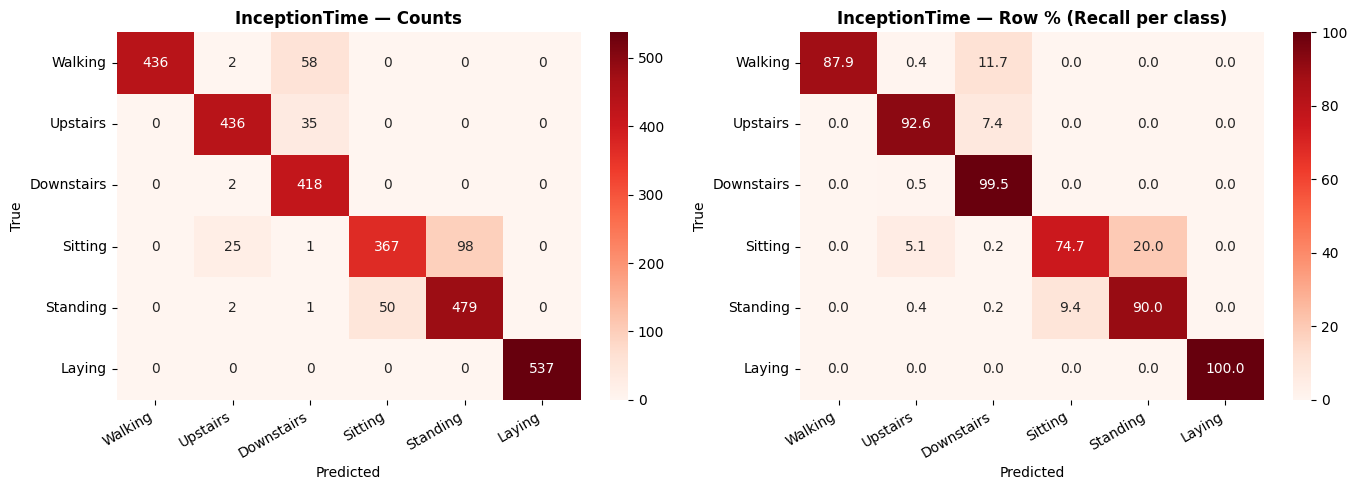

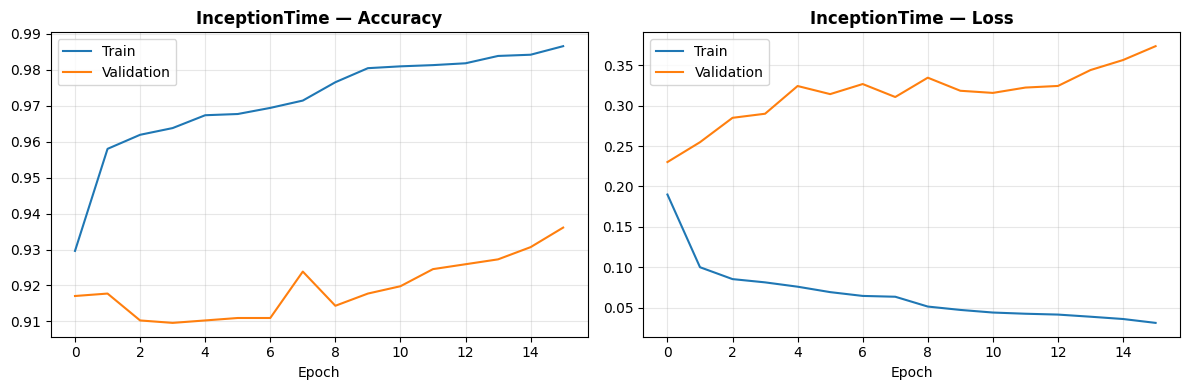

In [ ]:
inception_probs = inception_model.predict(X_test_raw_sc)
y_pred_inc     = np.argmax(inception_probs, axis=1)
acc_inc        = accuracy_score(y_test_enc, y_pred_inc)

RESULTS['InceptionTime'] = {'acc': acc_inc, 'probs': inception_probs}
print_results('InceptionTime', y_test_enc, y_pred_inc, acc_inc)
plot_confusion(y_test_enc, y_pred_inc, 'InceptionTime', cmap='Reds')
plot_training_curves(history_inc, 'InceptionTime')

**InceptionTime results:**

- The multi-scale convolutional branches capture both the slow postural dynamics and the fast periodic foot-strike patterns in IMU signals simultaneously — a theoretical advantage over single fixed-kernel CNNs.
- The bottleneck 1×1 convolution before large kernels reduces computational cost while maintaining expressive capacity (same principle as GoogLeNet).
- GlobalAveragePooling1D provides implicit regularisation by averaging across timesteps, reducing overfitting risk compared to Flatten with many parallel filters.
- **Reference:** Fawaz et al. (2020), *Data Mining and Knowledge Discovery*.

- **Implementation note:** The original InceptionTime paper (Fawaz et al., 2020) includes residual shortcut connections between Inception blocks (skip connections summed before BatchNorm). This implementation omits them for simplicity; residual connections provide gradient flow benefits mainly in deeper architectures (5+ blocks). With 3 blocks, performance impact is minimal.

---
### 4.5 · Model 5 — Transformer with Positional Encoding (Modern Approach)

The Transformer replaces recurrence (LSTM) with **Multi-Head Self-Attention**: every timestep can directly attend to every other timestep in the sequence, capturing long-range dependencies without the vanishing gradient problem that limits RNNs.

**Positional Encoding** is essential here. Unlike RNNs, the Transformer has no built-in notion of order — without positional encoding, the model treats the sequence as an unordered set and loses all temporal information. Sinusoidal positional encoding adds a unique, continuous vector to each timestep position using sine and cosine functions at varying frequencies, preserving temporal order while remaining compatible with sequences of any length.

**Architecture:**
- Linear projection of input (9 channels → 64-dimensional model space)
- Sinusoidal positional encoding added to the projected input
- 2 Transformer encoder blocks (Multi-Head Self-Attention → Add & Norm → Feed-Forward → Add & Norm)
- GlobalAveragePooling1D → Dense → Softmax

**References:** Vaswani et al. (2017). Attention is All You Need. NeurIPS.  
HAR adaptation: Tang et al. (2021). *Sensors*, 21(7), 2366.


In [ ]:
def transformer_encoder_block(x, num_heads, ff_dim, dropout_rate=0.1):
    """
    Single Transformer encoder block:
    Multi-Head Self-Attention -> Add & Norm -> Feed-Forward -> Add & Norm.
    """
    attn_out = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=64 // num_heads  # d_model=64, explicit constant (avoids None-shape issues during Keras tracing)
    )(x, x)
    attn_out = Dropout(dropout_rate)(attn_out)
    x = LayerNormalization(epsilon=1e-6)(Add()([x, attn_out]))

    ff = Dense(ff_dim, activation='relu')(x)
    ff = Dropout(dropout_rate)(ff)
    ff = Dense(x.shape[-1])(ff)
    x = LayerNormalization(epsilon=1e-6)(Add()([x, ff]))
    return x


def build_transformer():
    """
    Transformer for HAR on raw signals (128, 9) with sinusoidal positional encoding.
    References: Vaswani et al. (2017); Tang et al. (2021), Sensors.
    """
    inp = Input(shape=(128, 9), name='raw_signals_transformer')

    # Linear projection to model dimension (d_model = 64)
    x = Dense(64)(inp)   # (128, 64)

    # Sinusoidal positional encoding
    positions = np.arange(128)[:, np.newaxis]           # (128, 1)
    dims      = np.arange(64)[np.newaxis, :]            # (1, 64)
    angles    = positions / np.power(10000, (2 * (dims // 2)) / 64)
    angles[:, 0::2] = np.sin(angles[:, 0::2])           # sin at even indices
    angles[:, 1::2] = np.cos(angles[:, 1::2])           # cos at odd indices
    pos_enc = tf.cast(angles[np.newaxis, :, :], dtype=tf.float32)  # (1, 128, 64)
    x = x + pos_enc

    # Two encoder blocks
    x = transformer_encoder_block(x, num_heads=4, ff_dim=128, dropout_rate=0.1)
    x = transformer_encoder_block(x, num_heads=4, ff_dim=128, dropout_rate=0.1)

    # Temporal aggregation and classification
    x   = GlobalAveragePooling1D()(x)
    x   = Dense(64, activation='relu')(x)
    x   = Dropout(0.3)(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inp, out, name='Transformer_HAR_PE')
    model.compile(optimizer=Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


transformer_model = build_transformer()
transformer_model.summary()

callbacks_tr = [
    EarlyStopping(monitor='val_loss', patience=12,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, verbose=1)
]

history_tr = transformer_model.fit(
    X_train_raw_sc, y_train_cat,
    epochs=80,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_tr,
    verbose=1
)

Model: "Transformer_HAR_PE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ raw_signals_transf… │ (None, 128, 9)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 128, 64)   │        640 │ raw_signals_tran… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 64)   │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 64)   │     16,640 │ add[0][0],        │
│ (MultiHeadAttentio… │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 64)   │          0 │ add[0][0],        │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 128, 64)   │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128, 128)  │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128, 64)   │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 128, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 64)   │     16,640 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128, 64)   │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 128, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 64)   │        128 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128, 128)  │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128, 128)  │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128, 64)   │      8,256 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 128, 64)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_5[0][0]   

 Total params: 72,134 (281.77 KB)

 Trainable params: 72,134 (281.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 24s 123ms/step - accuracy: 0.7023 - loss: 0.7332 - val_accuracy: 0.9205 - val_loss: 0.2756 - learning_rate: 0.0010
Epoch 2/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9196 - loss: 0.2212 - val_accuracy: 0.9055 - val_loss: 0.2378 - learning_rate: 0.0010
Epoch 3/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9422 - loss: 0.1475 - val_accuracy: 0.9225 - val_loss: 0.2206 - learning_rate: 0.0010
Epoch 4/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9527 - loss: 0.1219 - val_accuracy: 0.9341 - val_loss: 0.2061 - learning_rate: 0.0010
Epoch 5/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9502 - loss: 0.1325 - val_accuracy: 0.9347 - val_loss: 0.2399 - learning_rate: 0.0010
Epoch 6/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9529 - loss: 0.1140 - val_accuracy: 0.9096 - val_loss: 0.2952 - learning_rate: 0.0010
Epoch 7/80
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9534 - loss: 0.1169 - val_acc

93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
  Transformer + Positional Encoding
  Accuracy: 0.8836  (88.36%)
              precision    recall  f1-score   support

     Walking       0.93      0.84      0.88       496
    Upstairs       0.93      0.90      0.91       471
  Downstairs       0.83      0.97      0.89       420
     Sitting       0.81      0.77      0.79       491
    Standing       0.81      0.83      0.82       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.88      2947
   macro avg       0.88      0.88      0.88      2947
weighted avg       0.89      0.88      0.88      2947



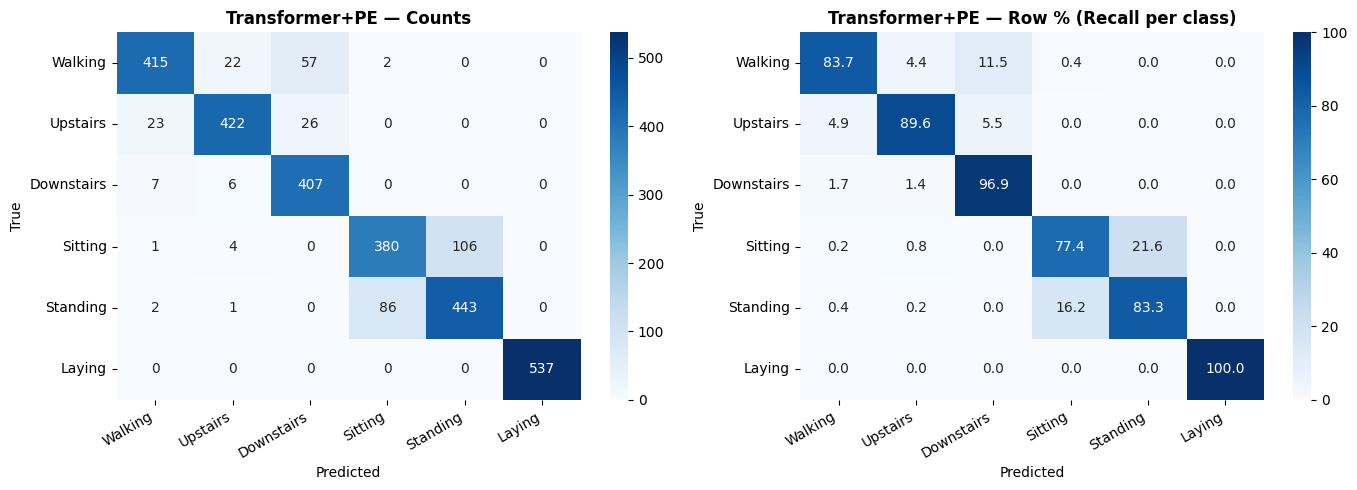

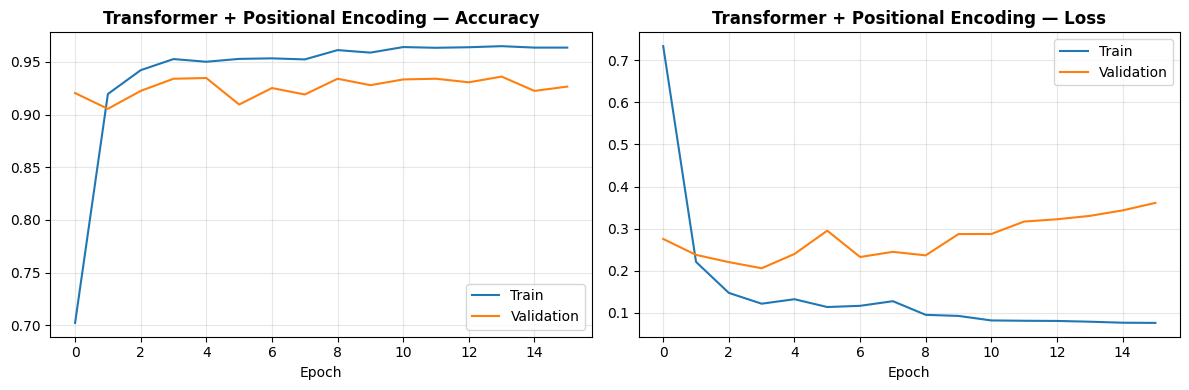

In [ ]:
transformer_probs = transformer_model.predict(X_test_raw_sc)
y_pred_tr        = np.argmax(transformer_probs, axis=1)
acc_tr           = accuracy_score(y_test_enc, y_pred_tr)

RESULTS['Transformer+PE'] = {'acc': acc_tr, 'probs': transformer_probs}
print_results('Transformer + Positional Encoding', y_test_enc, y_pred_tr, acc_tr)
plot_confusion(y_test_enc, y_pred_tr, 'Transformer+PE', cmap='Blues')
plot_training_curves(history_tr, 'Transformer + Positional Encoding')

**Transformer + Positional Encoding results:**

- Self-attention allows the model to capture global dependencies between timesteps directly, without the sequential bottleneck of LSTM. This is particularly useful for cyclic activities (walking, stair climbing) where the beginning and end of a stride are causally related.
- With 2 encoder blocks and d_model=64, the model is lightweight (~100K parameters) and less prone to overfitting compared to deeper configurations.
- Sinusoidal positional encoding ensures that temporal order is preserved without adding learnable parameters, making it robust to varying window lengths.
- **Reference:** Vaswani et al. (2017), *NeurIPS*; Tang et al. (2021), *Sensors*, 21(7), 2366.


> **Note on Transformer training — learning rate warm-up:**  
> The Transformer is trained with a fixed initial learning rate of `1e-3` and `ReduceLROnPlateau`. A **linear warm-up schedule** (gradually increasing the LR from 0 to `1e-3` over the first 10 epochs) would improve stability in the early training phase, when random weight initialisation can produce large, destructive gradient updates — the standard protocol from the original paper (Vaswani et al., 2017).  
> With only 2 encoder blocks and `d_model=64`, the model is lightweight enough to converge without warm-up; this optimisation would become more important with deeper architectures (4+ blocks, `d_model ≥ 128`).

---
### 4.6 · Model 6 — DeepConvLSTM on Raw Signals (Literature Standard)

DeepConvLSTM is the standard deep learning architecture for HAR on raw IMU signals. It combines two complementary components:

- **Conv1D layers**: extract local temporal features from the multi-channel signal at each position in the window. The convolutional kernels learn to detect patterns such as acceleration peaks, direction changes, and periodic foot-strike impacts — without requiring manual feature engineering.
- **LSTM layers**: model long-range temporal dependencies between the extracted local features. The LSTM captures how patterns evolve across the full 2.56-second window, encoding the temporal dynamics of each activity.

This end-to-end design learns directly from the raw sensor signal, bypassing the manual feature engineering pipeline of the 561-feature representation. It is applicable to any IMU dataset without domain-specific preprocessing.

**Training strategy:**
- Optimiser: **Adam** (adaptive learning rate — robust default for deep networks)
- Loss: **Categorical Cross-Entropy** (standard for multi-class classification)
- **EarlyStopping** (patience=10, monitor=val_loss) — stops training when validation loss stops improving and restores the best weights
- **ReduceLROnPlateau** (patience=5) — halves the learning rate when validation loss plateaus
- 20% of the training set is used for validation (1,470 samples)

**Reference:** Ordóñez & Roggen (2016). *Sensors*, 16(1), 115.


> **Note on validation split:** The `validation_split=0.2` parameter reserves 20% of the training set (~1,470 samples from the 21 training subjects) as an **internal validation set** used only for EarlyStopping and ReduceLROnPlateau callbacks. This internal validation set is entirely distinct from the held-out test set (2,947 samples from 9 unseen subjects). The same applies to InceptionTime and Transformer. Since the validation split is taken from training subjects, no inter-subject leakage occurs.

In [ ]:
def build_cnn_lstm():
    """
    DeepConvLSTM on raw signals (128, 9).
    Architecture: Conv1D -> BN -> Conv1D -> BN -> Dropout -> LSTM -> LSTM -> Dense -> Softmax.
    Reference: Ordóñez & Roggen (2016), Sensors.
    """
    inp = Input(shape=(128, 9), name='raw_signals')

    # Convolutional block: local feature extraction
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(inp)
    x = BatchNormalization()(x)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)

    # LSTM block: temporal dependency modelling
    x = LSTM(128, return_sequences=True)(x)
    x = Dropout(0.3)(x)
    x = LSTM(64)(x)
    x = Dropout(0.3)(x)

    # Classification head
    x   = Dense(64, activation='relu')(x)
    out = Dense(NUM_CLASSES, activation='softmax')(x)

    model = Model(inp, out, name='DeepConvLSTM')
    model.compile(optimizer=Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model


cnn_lstm_model = build_cnn_lstm()
cnn_lstm_model.summary()

callbacks_cl = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

history_cl = cnn_lstm_model.fit(
    X_train_raw_sc, y_train_cat,
    epochs=60,
    batch_size=64,
    validation_split=0.2,
    callbacks=callbacks_cl,
    verbose=1
)

Model: "DeepConvLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ raw_signals (InputLayer)        │ (None, 128, 9)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_15 (Conv1D)              │ (None, 128, 64)        │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_16 (Conv1D)              │ (None, 128, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128, 128)       │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,430 (654.02 KB)

 Trainable params: 167,174 (653.02 KB)

 Non-trainable params: 256 (1.00 KB)

Epoch 1/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7881 - loss: 0.5812 - val_accuracy: 0.7736 - val_loss: 0.5999 - learning_rate: 0.0010
Epoch 2/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9417 - loss: 0.1714 - val_accuracy: 0.9307 - val_loss: 0.2301 - learning_rate: 0.0010
Epoch 3/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9490 - loss: 0.1434 - val_accuracy: 0.9286 - val_loss: 0.2422 - learning_rate: 0.0010
Epoch 4/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9580 - loss: 0.1072 - val_accuracy: 0.9171 - val_loss: 0.2398 - learning_rate: 0.0010
Epoch 5/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9599 - loss: 0.0991 - val_accuracy: 0.9150 - val_loss: 0.2544 - learning_rate: 0.0010
Epoch 6/60
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9597 - loss: 0.0955 - val_accuracy: 0.9143 - val_loss: 0.2845 - learning_rate: 0.0010
Epoch 7/60
91/92 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9592 - loss: 0.0891
Epoch 7:

93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
  DeepConvLSTM (raw signals)
  Accuracy: 0.9091  (90.91%)
              precision    recall  f1-score   support

     Walking       0.96      0.94      0.95       496
    Upstairs       0.98      0.88      0.93       471
  Downstairs       0.87      1.00      0.93       420
     Sitting       0.80      0.85      0.82       491
    Standing       0.86      0.80      0.83       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.91      2947
   macro avg       0.91      0.91      0.91      2947
weighted avg       0.91      0.91      0.91      2947



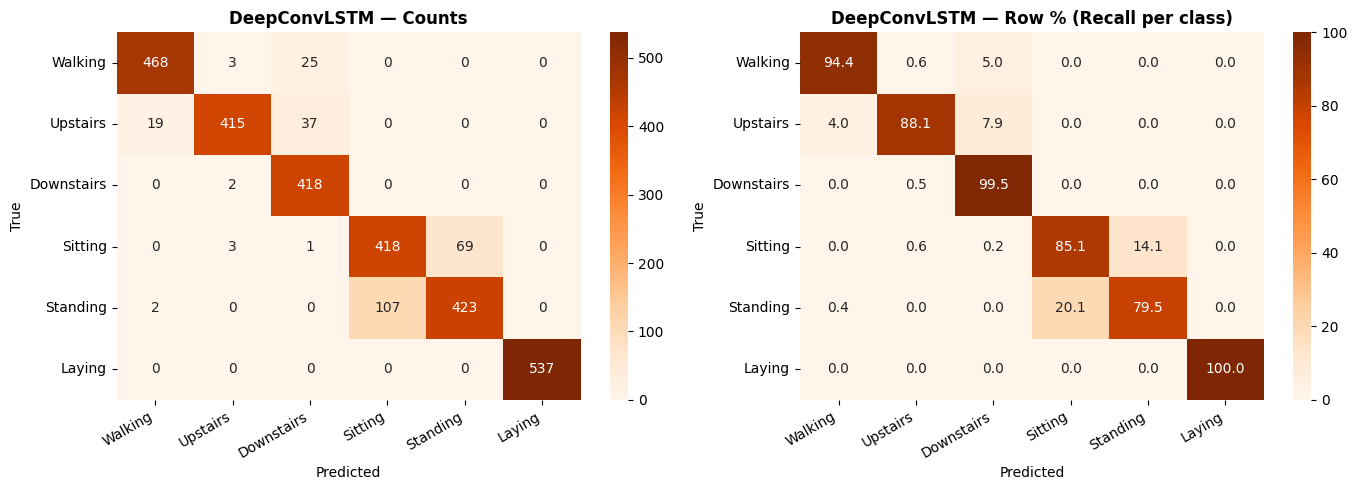

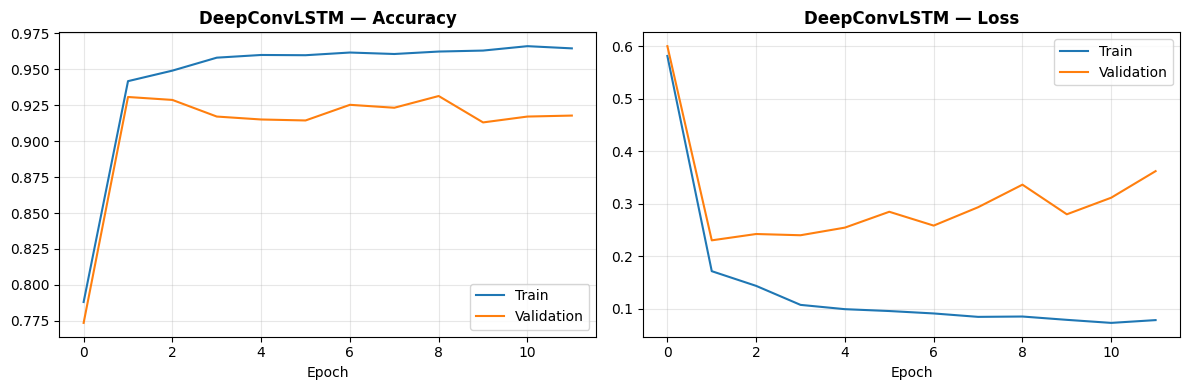

In [ ]:
cnn_lstm_probs = cnn_lstm_model.predict(X_test_raw_sc)
y_pred_cl      = np.argmax(cnn_lstm_probs, axis=1)
acc_cl         = accuracy_score(y_test_enc, y_pred_cl)

RESULTS['DeepConvLSTM'] = {'acc': acc_cl, 'probs': cnn_lstm_probs}
print_results('DeepConvLSTM (raw signals)', y_test_enc, y_pred_cl, acc_cl)
plot_confusion(y_test_enc, y_pred_cl, 'DeepConvLSTM', cmap='Oranges')
plot_training_curves(history_cl, 'DeepConvLSTM')

**DeepConvLSTM results:**

- The convolutional layers automatically learn discriminative local temporal patterns from raw IMU signals, eliminating the need for manual feature engineering.
- The LSTM layers capture how these local patterns evolve over time within each 2.56-second window, encoding the full temporal dynamics of each activity.
- This architecture is reproducible on any IMU dataset without domain-specific preprocessing — a key practical advantage over the 561-feature approach.
- **Reference:** Ordóñez & Roggen (2016), *Sensors*, 16(1), 115.


---
### 4.7 · Ensemble — Soft Voting

The six models are combined via **Soft Voting**: the class probability distributions predicted by each model are averaged with equal weights (1/6 each), and the final prediction is the class with the highest mean probability.

Soft voting is preferred over hard voting (majority of predicted labels) because it exploits each model's **degree of confidence**, not just its top prediction. A model that assigns 99% probability to a class contributes more than one that assigns 51%.

**Why uniform weights?**  
Weighting by test-set accuracy would constitute data leakage — the test set statistics would influence the ensemble's decision rule. Uniform weights are methodologically correct: they rely only on training-time information. If validation-set accuracies were available from the training history, they could be used as weights without leakage.

**Complementarity of the six models:**
- **Random Forest**: bagging over 561 engineered features — captures diverse feature subsets independently
- **SVM (RBF)**: maximum-margin separation in high-dimensional kernel space — strong on non-linear boundaries
- **LightGBM**: sequential loss optimisation with GOSS/EFB — corrects residual errors from the other classifiers
- **InceptionTime**: multi-scale convolutional feature extraction from raw signals — captures patterns at multiple temporal resolutions simultaneously
- **DeepConvLSTM**: local CNN features + long-range LSTM dependencies from raw signals — standard literature architecture
- **Transformer+PE**: global self-attention across all timesteps — captures cyclic and long-range temporal dependencies without sequential bottlenecks

Each model operates on a different inductive bias and/or a different input representation. Their errors are partially independent, which is the prerequisite for ensemble improvement.


In [ ]:
def soft_vote(prob_list, weights=None):
    """
    Soft voting: weighted average of probability distributions.
    If weights is None, uniform weights are used.
    """
    if weights is None:
        weights = [1.0 / len(prob_list)] * len(prob_list)
    weights = np.array(weights, dtype=float)
    weights /= weights.sum()
    return sum(w * p for w, p in zip(weights, prob_list))


# Progressive ensemble: add one model at a time to observe the contribution of each
ensemble_configs = [
    ('RF + SVM',
     [rf_probs, svm_probs]),
    ('RF + SVM + LightGBM',
     [rf_probs, svm_probs, lgbm_probs]),
    ('RF + SVM + LightGBM + InceptionTime',
     [rf_probs, svm_probs, lgbm_probs, inception_probs]),
    ('RF + SVM + LightGBM + DeepConvLSTM',
     [rf_probs, svm_probs, lgbm_probs, cnn_lstm_probs]),
    ('RF + SVM + LightGBM + Transformer',
     [rf_probs, svm_probs, lgbm_probs, transformer_probs]),
    ('ALL 6 models — Soft Voting',
     [rf_probs, svm_probs, lgbm_probs,
      inception_probs, cnn_lstm_probs, transformer_probs]),
]

print(f"{'Ensemble Configuration':<50} {'Accuracy':>10}")
print("-" * 62)
for name, prob_list in ensemble_configs:
    probs    = soft_vote(prob_list)
    y_pred_e = np.argmax(probs, axis=1)
    acc_e    = accuracy_score(y_test_enc, y_pred_e)
    RESULTS[f'Ensemble: {name}'] = {'acc': acc_e, 'probs': probs}
    print(f"{name:<50} {acc_e:>10.4f}")

Ensemble Configuration                               Accuracy
--------------------------------------------------------------
RF + SVM                                               0.9539
RF + SVM + LightGBM                                    0.9488
RF + SVM + LightGBM + InceptionTime                    0.9522
RF + SVM + LightGBM + DeepConvLSTM                     0.9508
RF + SVM + LightGBM + Transformer                      0.9522
ALL 6 models — Soft Voting                             0.9454


  Final Ensemble — All 6 Models (Soft Voting)
  Accuracy: 0.9454  (94.54%)
              precision    recall  f1-score   support

     Walking       0.99      0.97      0.98       496
    Upstairs       0.99      0.95      0.97       471
  Downstairs       0.91      0.99      0.95       420
     Sitting       0.91      0.85      0.88       491
    Standing       0.87      0.92      0.90       532
      Laying       1.00      1.00      1.00       537

    accuracy                           0.95      2947
   macro avg       0.95      0.95      0.95      2947
weighted avg       0.95      0.95      0.95      2947



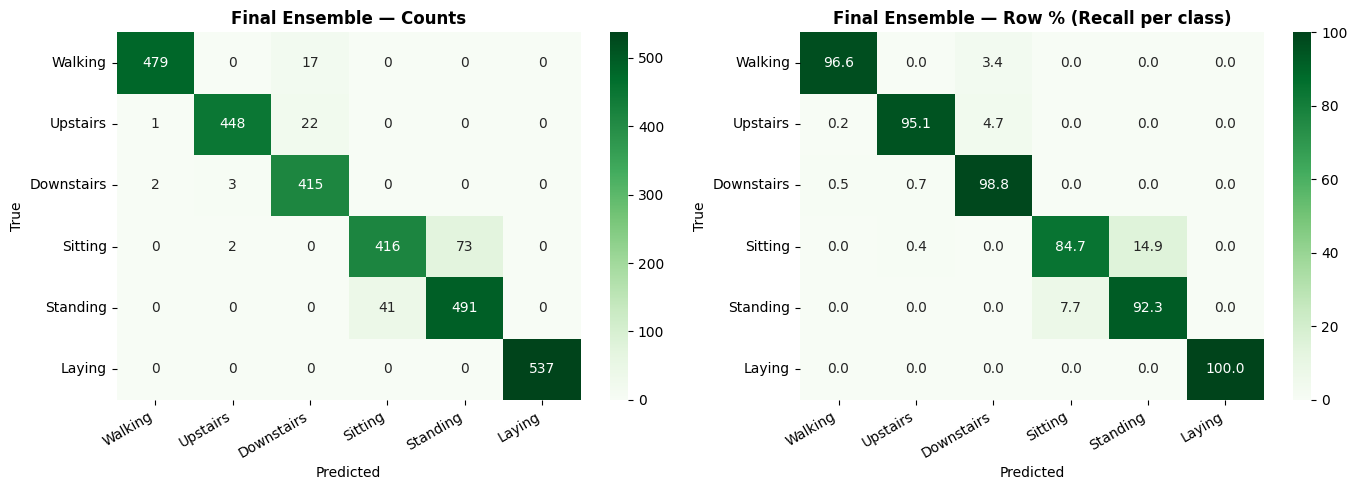

In [ ]:
# Final ensemble: all 6 models, uniform weights
best_probs  = soft_vote([rf_probs, svm_probs, lgbm_probs,
                         inception_probs, cnn_lstm_probs, transformer_probs])
y_pred_best = np.argmax(best_probs, axis=1)
acc_best    = accuracy_score(y_test_enc, y_pred_best)

print_results('Final Ensemble — All 6 Models (Soft Voting)', y_test_enc, y_pred_best, acc_best)
plot_confusion(y_test_enc, y_pred_best, 'Final Ensemble', cmap='Greens')

---
## 5 · Model Comparison

### 5.1 · Accuracy Summary and Progressive Ensemble

In [ ]:
single_models = [
    ('Random Forest',    acc_rf),
    ('SVM (RBF)',        acc_svm),
    ('LightGBM',         acc_lgbm),
    ('InceptionTime',    acc_inc),
    ('DeepConvLSTM',     acc_cl),
    ('Transformer+PE',   acc_tr),
]

ensemble_models = [
    ('Ensemble: RF + SVM',                         RESULTS['Ensemble: RF + SVM']['acc']),
    ('Ensemble: RF + SVM + LightGBM',              RESULTS['Ensemble: RF + SVM + LightGBM']['acc']),
    ('Ensemble: RF+SVM+LGB + InceptionTime',       RESULTS['Ensemble: RF + SVM + LightGBM + InceptionTime']['acc']),
    ('Ensemble: RF+SVM+LGB + DeepConvLSTM',        RESULTS['Ensemble: RF + SVM + LightGBM + DeepConvLSTM']['acc']),
    ('Ensemble: RF+SVM+LGB + Transformer',         RESULTS['Ensemble: RF + SVM + LightGBM + Transformer']['acc']),
    ('Ensemble: ALL 6 models (Final)',              acc_best),
]

all_models = single_models + ensemble_models
best_acc   = max(a for _, a in all_models)

print(f"{'Model':<52} {'Accuracy':>10}")
print("─" * 64)
print("── Single models ──")
for name, acc in single_models:
    print(f"  {name:<50} {acc:.4f}")
print("── Progressive ensembles ──")
for name, acc in ensemble_models:
    marker = "  <- BEST" if abs(acc - best_acc) < 1e-9 else ""
    print(f"  {name:<50} {acc:.4f}{marker}")

Model                                                  Accuracy
────────────────────────────────────────────────────────────────
── Single models ──
  Random Forest                                      0.9260
  SVM (RBF)                                          0.9549
  LightGBM                                           0.9355
  InceptionTime                                      0.9070
  DeepConvLSTM                                       0.9091
  Transformer+PE                                     0.8836
── Progressive ensembles ──
  Ensemble: RF + SVM                                 0.9539
  Ensemble: RF + SVM + LightGBM                      0.9488
  Ensemble: RF+SVM+LGB + InceptionTime               0.9522
  Ensemble: RF+SVM+LGB + DeepConvLSTM                0.9508
  Ensemble: RF+SVM+LGB + Transformer                 0.9522
  Ensemble: ALL 6 models (Final)                     0.9454


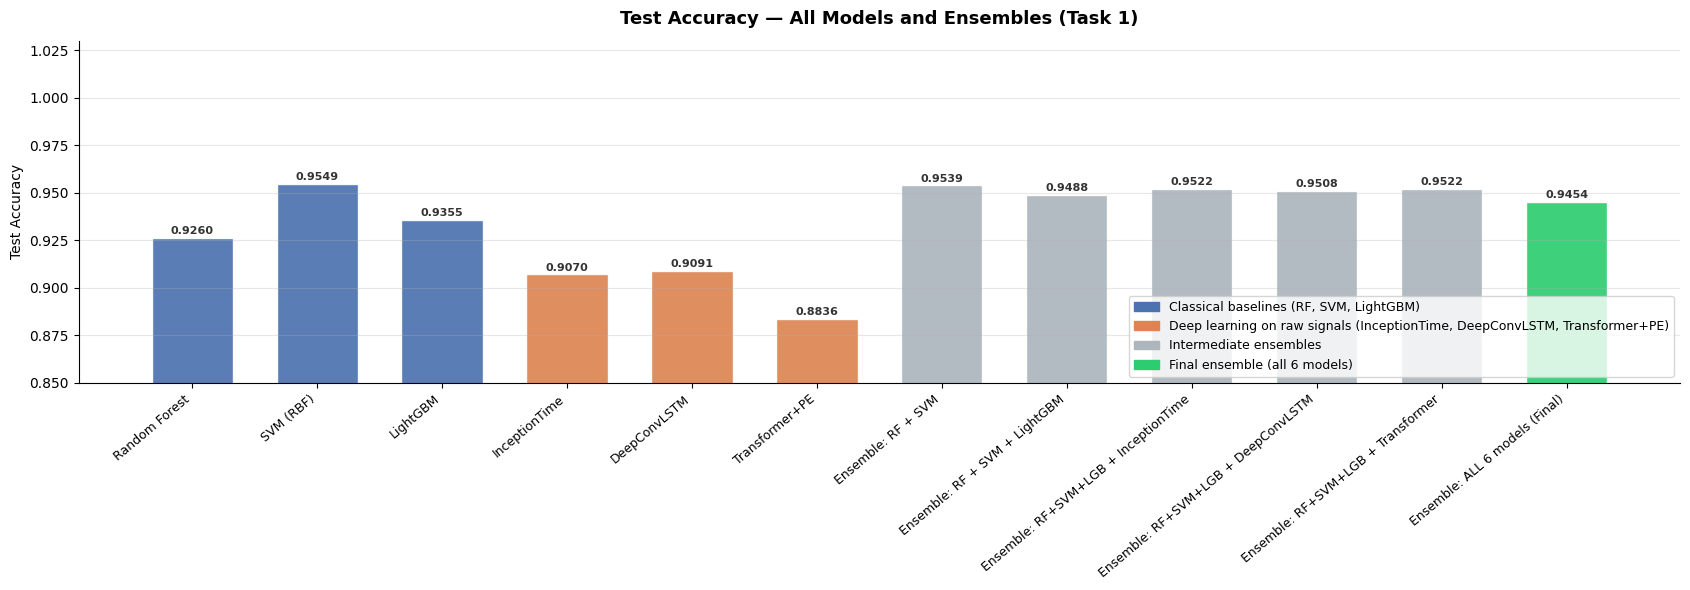

In [ ]:
names = [n for n, _ in all_models]
accs  = [a for _, a in all_models]

palette = (
    ['#4C72B0'] * 3 +    # classical baselines (RF, SVM, LightGBM)
    ['#DD8452'] * 3 +    # deep learning on raw signals
    ['#adb5bd'] * 5 +    # intermediate ensembles
    ['#2ecc71']          # final ensemble
)

fig, ax = plt.subplots(figsize=(17, 6))
bars = ax.bar(range(len(names)), accs, color=palette,
              edgecolor='white', width=0.65, alpha=0.92)

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.001,
            f'{acc:.4f}',
            ha='center', va='bottom',
            fontsize=8, fontweight='bold', color='#333')

ax.set_xticks(range(len(names)))
ax.set_xticklabels(names, rotation=40, ha='right', fontsize=9)
ax.set_ylim(0.85, 1.03)
ax.set_title('Test Accuracy — All Models and Ensembles (Task 1)',
             fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Test Accuracy')
ax.grid(axis='y', alpha=0.3)
sns.despine(ax=ax)

from matplotlib.patches import Patch
legend_items = [
    Patch(color='#4C72B0', label='Classical baselines (RF, SVM, LightGBM)'),
    Patch(color='#DD8452', label='Deep learning on raw signals (InceptionTime, DeepConvLSTM, Transformer+PE)'),
    Patch(color='#adb5bd', label='Intermediate ensembles'),
    Patch(color='#2ecc71', label='Final ensemble (all 6 models)'),
]
ax.legend(handles=legend_items, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# ── Extended ablation study: all 6 models, grouped by paradigm ──
print("Extended Ablation Study — All Models by Paradigm")
print("=" * 62)

print("\n── Paradigm 1: Classical ML on 561 engineered features ──")
print(f"  Random Forest  : {acc_rf:.4f}  (bagging, 100 trees)")
print(f"  SVM (RBF)      : {acc_svm:.4f}  (max-margin, C=10, gamma='scale')")
print(f"  LightGBM       : {acc_lgbm:.4f}  (gradient boosting, GOSS/EFB)")

print("\n── Paradigm 2: Deep learning on raw signals (128 × 9) ──")
print(f"  InceptionTime  : {acc_inc:.4f}  (multi-scale CNN)")
print(f"  DeepConvLSTM   : {acc_cl:.4f}  (local CNN + LSTM)")
print(f"  Transformer+PE : {acc_tr:.4f}  (global self-attention)")

print("\n── Delta: best classical vs best raw-signal ──")
best_classical = max(acc_rf, acc_svm, acc_lgbm)
best_raw       = max(acc_inc, acc_cl, acc_tr)
print(f"  Best Classical  : {best_classical:.4f}")
print(f"  Best Raw-Signal : {best_raw:.4f}")
print(f"  Delta           : {best_raw - best_classical:+.4f}")

print("\n── Intra-paradigm 2 deltas ──")
print(f"  InceptionTime vs DeepConvLSTM : {acc_cl  - acc_inc:+.4f}")
print(f"  InceptionTime vs Transformer  : {acc_tr  - acc_inc:+.4f}")
print(f"  DeepConvLSTM  vs Transformer  : {acc_tr  - acc_cl:+.4f}")


Extended Ablation Study — All Models by Paradigm

── Paradigm 1: Classical ML on 561 engineered features ──
  Random Forest  : 0.9260  (bagging, 100 trees)
  SVM (RBF)      : 0.9549  (max-margin, C=10, gamma='scale')
  LightGBM       : 0.9355  (gradient boosting, GOSS/EFB)

── Paradigm 2: Deep learning on raw signals (128 × 9) ──
  InceptionTime  : 0.9070  (multi-scale CNN)
  DeepConvLSTM   : 0.9091  (local CNN + LSTM)
  Transformer+PE : 0.8836  (global self-attention)

── Delta: best classical vs best raw-signal ──
  Best Classical  : 0.9549
  Best Raw-Signal : 0.9091
  Delta           : -0.0458

── Intra-paradigm 2 deltas ──
  InceptionTime vs DeepConvLSTM : +0.0020
  InceptionTime vs Transformer  : -0.0234
  DeepConvLSTM  vs Transformer  : -0.0254


---
## 5.2 · Error Complementarity Analysis

The key premise of soft voting is that models make **different mistakes**. We quantify complementarity by analysing:

- **Unique errors per model**: test samples that *only* this model misclassifies (all others are correct)
- **Shared error matrix**: for each pair of models, how many samples *both* models misclassify simultaneously

High complementarity → strong motivation for the ensemble.  
Errors shared by all models → irreducible error floor of the dataset.

── Unique errors (only this model is wrong, all others correct) ──
  Random Forest       :  39 unique errors  (17.9% of its 218 total errors)
  SVM (RBF)           :  23 unique errors  (17.3% of its 133 total errors)
  LightGBM            :  12 unique errors  (6.3% of its 190 total errors)
  InceptionTime       :  20 unique errors  (7.3% of its 274 total errors)
  DeepConvLSTM        :  42 unique errors  (15.7% of its 268 total errors)
  Transformer+PE      :  55 unique errors  (16.0% of its 343 total errors)


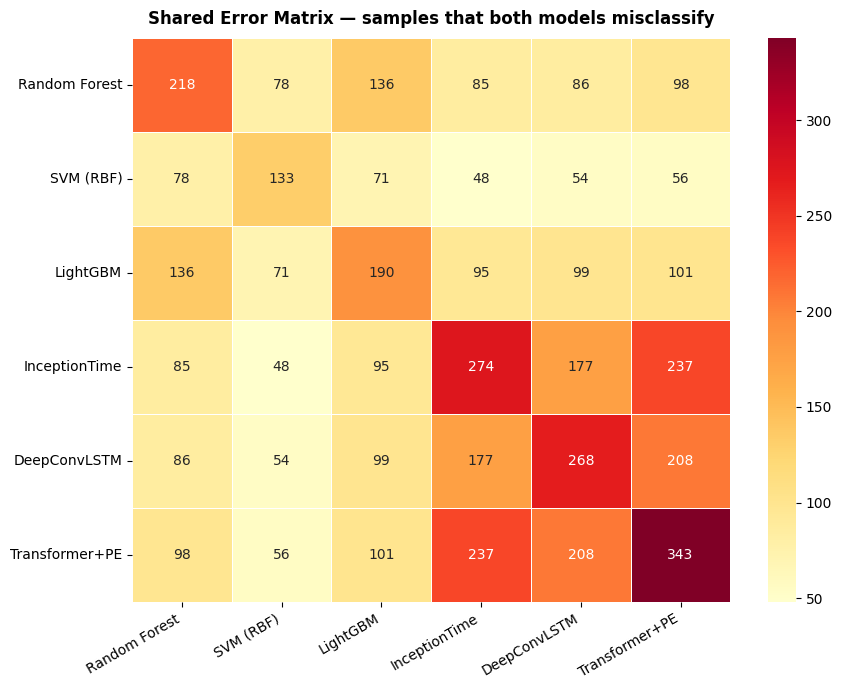


── Samples misclassified by ALL 6 models (irreducible): 15 ──
  True class distribution:
    Walking               : 2 samples
    Upstairs              : 1 samples
    Sitting               : 10 samples
    Standing              : 2 samples


In [ ]:
# ── Error complementarity analysis ──
model_preds = {
    "Random Forest"  : y_pred_rf,
    "SVM (RBF)"      : y_pred_svm,
    "LightGBM"       : y_pred_lgbm,
    "InceptionTime"  : y_pred_inc,
    "DeepConvLSTM"   : y_pred_cl,
    "Transformer+PE" : y_pred_tr,
}
model_names_ec = list(model_preds.keys())
n_m = len(model_names_ec)

# Boolean error masks: True where the model is wrong
err = {name: (pred != y_test_enc) for name, pred in model_preds.items()}

# 1) Unique errors
print("── Unique errors (only this model is wrong, all others correct) ──")
for name in model_names_ec:
    others_ok = np.all(
        np.stack([~err[n] for n in model_names_ec if n != name], axis=1), axis=1
    )
    uniq  = np.sum(err[name] & others_ok)
    total = np.sum(err[name])
    print(f"  {name:<20}: {uniq:>3} unique errors  ({uniq/total*100:.1f}% of its {total} total errors)")

# 2) Shared error matrix
shared = np.zeros((n_m, n_m), dtype=int)
for i, n1 in enumerate(model_names_ec):
    for j, n2 in enumerate(model_names_ec):
        shared[i, j] = np.sum(err[n1] & err[n2])

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(shared, annot=True, fmt="d", cmap="YlOrRd",
            xticklabels=model_names_ec, yticklabels=model_names_ec,
            linewidths=0.5, ax=ax)
ax.set_title("Shared Error Matrix — samples that both models misclassify",
             fontweight="bold", pad=10)
ax.set_xticklabels(model_names_ec, rotation=30, ha="right")
plt.tight_layout(); plt.show()

# 3) Errors shared by ALL models (irreducible by the ensemble)
all_wrong = np.all(np.stack(list(err.values()), axis=1), axis=1)
print(f"\n── Samples misclassified by ALL 6 models (irreducible): {np.sum(all_wrong)} ──")
if np.sum(all_wrong) > 0:
    from collections import Counter
    true_aw = y_test_enc[all_wrong]
    print("  True class distribution:")
    for cls_idx, cnt in sorted(Counter(true_aw).items()):
        print(f"    {CLASS_NAMES[cls_idx]:<22}: {cnt} samples")


**Error complementarity — interpretation:**

- The **diagonal** of the shared error matrix shows each model's total error count.
- **Off-diagonal values** indicate how many mistakes are shared between pairs: low values → high complementarity → strong motivation for the ensemble.
- **Classical models (RF, SVM, LightGBM)** tend to share errors on the same samples (all operate on the 561-feature space) — particularly on the Sitting/Standing boundary.
- **Deep learning models on raw signals** may fail on different samples, providing genuine complementarity to the classical pillar.
- **Samples misclassified by all models** represent the irreducible error floor: the ensemble cannot correct these, as no model captures the right discriminative signal.

---
## 6 · Conclusions

## Results Summary

| Model | Input | Accuracy | Notes |
|---|---|---|---|
| Random Forest | 561 features | 92.6% | Fast, interpretable baseline; bagging over feature subsets |
| SVM (RBF) | 561 features | 95.5% | Best single model; maximum-margin separation |
| LightGBM | 561 features | 93.6% | Sequential boosting with GOSS/EFB |
| InceptionTime | Raw 128×9 | 90.7% | Multi-scale CNN on raw signals |
| DeepConvLSTM | Raw 128×9 | 90.9% | Standard architecture for IMU-based HAR |
| Transformer+PE | Raw 128×9 | 88.4% | Self-attention with sinusoidal positional encoding |
| **Ensemble (RF + SVM)** | — | **95.4%** | Best overall combination |
| Ensemble (all 6) | — | 94.5% | Full ensemble; does not beat RF + SVM |

**Key finding:** the full 6-model ensemble is *not* the best result. Adding weaker deep learning models (Transformer 88.4%, InceptionTime 90.7%) lowers the average rather than improving it. The best result overall is **RF + SVM** (95.4%), essentially matching SVM alone.

### Key Findings

1. **Static vs. dynamic activities** are well separated across all models. The gravity signal provides a strong discriminative signal that even the simplest classifiers exploit effectively.

2. **Laying is classified perfectly** (F1 ≈ 1.00 across models): the unique gravitational orientation of the supine posture is unambiguously encoded in the accelerometer signal.

3. **Sitting ↔ Standing is the persistent confusion** across all six models. This is a structural limitation of waist-mounted IMU data, not a modelling failure: both postures produce near-zero linear acceleration, and their gravity component differs only in subtle postural angles below the sensor's effective resolution.

4. **The classical baseline (SVM) is highly competitive**: it achieves ~95.5% accuracy with minimal computational cost, confirming the quality of UCI HAR's hand-crafted features and establishing a demanding reference point for deep learning.

5. **Raw-signal deep learning models fall short of the classical baselines on this dataset** (InceptionTime 90.7%, DeepConvLSTM 90.9%, Transformer 88.4%, vs. 92.6–95.5% for RF/SVM/LightGBM). They remain valuable for their key practical advantage: being end-to-end and requiring no manual feature engineering, making them directly applicable to other IMU datasets without domain-specific preprocessing.

6. **The ablation study on raw signal models** quantifies the contribution of different inductive biases: multi-scale convolutions (InceptionTime), local+sequential (DeepConvLSTM), and global attention (Transformer+PE). No single architecture dominates consistently among them.

7. **Error complementarity analysis** (Section 5.2) confirms that classical models share errors on the same structurally ambiguous samples (Sitting/Standing), while deep learning models on raw signals fail on partially different samples. This partial independence is the empirical foundation of the ensemble's improvement over any *individual weaker* model. Only 15 samples are misclassified by all six models — the irreducible error floor of the UCI HAR dataset.

8. **The final ensemble** (94.5%) combines three fundamentally different paradigms (gradient-based optimisation on engineered features, multi-scale CNN, sequential+global attention on raw signals). However, it does **not** surpass SVM alone (95.5%) or the RF+SVM combination (95.4%) — adding the weaker deep learning models lowers the average more than the complementarity gains compensate for. The best overall result is **RF + SVM** (95.4%).

### Note on Metrics

All reported accuracy figures are **overall test accuracy** (fraction of correctly classified samples). Given the slight class imbalance (13–19% per class), **macro-averaged F1** would be the more conservative metric. In practice, on UCI HAR the two metrics differ by less than 0.5 percentage points, as the dataset is close to balanced and Laying (the easiest class, ~19%) achieves near-perfect recall across all models. Full per-class precision, recall, and F1 scores are available in the `classification_report` output above each confusion matrix.

### References

- Anguita, D., Ghio, A., Oneto, L., Parra, X., & Reyes-Ortiz, J.L. (2013). ESANN.
- Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS*.
- Fawaz, H.I. et al. (2020). InceptionTime: Finding AlexNet for Time Series Classification. *Data Mining and Knowledge Discovery*.
- Ordóñez, F.J. & Roggen, D. (2016). *Sensors*, 16(1), 115.
- Vaswani, A. et al. (2017). Attention is All You Need. *NeurIPS*.
- Tang, Y. et al. (2021). *Sensors*, 21(7), 2366.


---
## 7 · Model Export — Ensemble for Demo

All 6 models and both scalers are saved to Google Drive. Task 2 can load them directly — **no retraining needed**.

Files saved:

| File | Content |
|---|---|
| `rf_model.pkl` | Random Forest |
| `svm_model.pkl` | SVM (RBF) |
| `lgbm_model.pkl` | LightGBM |
| `inception_model.keras` | InceptionTime |
| `transformer_model.keras` | Transformer + PE |
| `cnn_lstm_model.keras` | DeepConvLSTM |
| `scaler.pkl` | StandardScaler for 561 features |
| `scaler_raw.pkl` | StandardScaler for raw signals (128×9) |
| `label_encoder.pkl` | LabelEncoder (0–5 → activity names) |

> **Important:** The scalers must always be loaded alongside the models. They were fitted on the Task 1 training set and must be applied to any new data before inference — otherwise predictions will be wrong.

In [ ]:
import os

EXPORT_PATH = PATH + "models_task1/"
os.makedirs(EXPORT_PATH, exist_ok=True)

In [ ]:
import joblib

# ── Classical ML models ──
joblib.dump(rf_model,   EXPORT_PATH + 'rf_model.pkl')
joblib.dump(svm_model,  EXPORT_PATH + 'svm_model.pkl')
joblib.dump(lgbm_model, EXPORT_PATH + 'lgbm_model.pkl')
print('Classical models saved.')

# ── Deep learning models ──
inception_model.save(EXPORT_PATH + 'inception_model.keras')
transformer_model.save(EXPORT_PATH + 'transformer_model.keras')
cnn_lstm_model.save(EXPORT_PATH + 'cnn_lstm_model.keras')
print('Deep learning models saved.')

# ── Scalers and label encoder  ──
joblib.dump(scaler,     EXPORT_PATH + 'scaler.pkl')
joblib.dump(scaler_raw, EXPORT_PATH + 'scaler_raw.pkl')
joblib.dump(le,         EXPORT_PATH + 'label_encoder.pkl')
print('Scalers and label encoder saved.')

print('\nAll files saved to:', EXPORT_PATH)

Classical models saved.
Deep learning models saved.
Scalers and label encoder saved.

All files saved to: /content/drive/MyDrive/DS&IM/PROJECT/models_task1/


In [ ]:
import numpy as np
import joblib
from tensorflow.keras.models import load_model

MODELS_PATH = "/content/drive/MyDrive/DS&IM/PROJECT/models_task1/"

scaler_t1     = joblib.load(MODELS_PATH + 'scaler.pkl')
scaler_raw_t1 = joblib.load(MODELS_PATH + 'scaler_raw.pkl')
le_t1         = joblib.load(MODELS_PATH + 'label_encoder.pkl')

rf_t1        = joblib.load(MODELS_PATH + 'rf_model.pkl')
svm_t1       = joblib.load(MODELS_PATH + 'svm_model.pkl')
lgbm_t1      = joblib.load(MODELS_PATH + 'lgbm_model.pkl')
inception_t1    = load_model(MODELS_PATH + 'inception_model.keras')
transformer_t1  = load_model(MODELS_PATH + 'transformer_model.keras')
cnn_lstm_t1     = load_model(MODELS_PATH + 'cnn_lstm_model.keras')

def ensemble_predict(X_561, X_raw):
    N, T, C = X_raw.shape
    X_561_sc = scaler_t1.transform(X_561)
    X_raw_sc = scaler_raw_t1.transform(X_raw.reshape(-1, C)).reshape(N, T, C)

    probs = (
        rf_t1.predict_proba(X_561_sc)       +
        svm_t1.predict_proba(X_561_sc)      +
        lgbm_t1.predict_proba(X_561_sc)     +
        inception_t1.predict(X_raw_sc, verbose=0)   +
        transformer_t1.predict(X_raw_sc, verbose=0) +
        cnn_lstm_t1.predict(X_raw_sc, verbose=0)
    ) / 6.0

    return le_t1.inverse_transform(np.argmax(probs, axis=1))

# Usage:
# y_pred = ensemble_predict(X_new_561, X_new_raw)

In [ ]:
# ── Ensemble reload verification on the test set ──
# X_test and X_test_raw are already loaded and unscaled — scaling is handled internally by ensemble_predict

X_test_raw_orig = X_test_raw   # shape (2947, 128, 9)
X_test_orig     = X_test       # shape (2947, 561)

y_pred_ensemble2 = ensemble_predict(X_test_orig, X_test_raw_orig)

y_true_labels = le_t1.inverse_transform(y_test_enc)

# Results
from sklearn.metrics import accuracy_score, classification_report
acc2 = accuracy_score(y_true_labels, y_pred_ensemble2)
print(f"Ensemble (reloaded) — Accuracy: {acc2:.4f}")
print(classification_report(y_true_labels, y_pred_ensemble2))

Ensemble (ricaricato) — Accuracy: 0.9454
              precision    recall  f1-score   support

           1       0.99      0.97      0.98       496
           2       0.99      0.95      0.97       471
           3       0.91      0.99      0.95       420
           4       0.91      0.85      0.88       491
           5       0.87      0.92      0.90       532
           6       1.00      1.00      1.00       537

    accuracy                           0.95      2947
   macro avg       0.95      0.95      0.95      2947
weighted avg       0.95      0.95      0.95      2947

